In [22]:
def get_mol_geo(phase=1):
    # 根据输入phase选择不同的晶体结构
    if phase == 1:
        # ① 单斜相ZrO2
        a = 5.15  # Å
        b = 5.23  # Å
        c = 5.33  # Å
        beta = 99.44 * np.pi / 180  # 弧度
        # 晶胞向量
        a_vec = np.array([a, 0, 0])
        b_vec = np.array([0, b, 0])
        c_vec = np.array([c * np.cos(beta), 0, c * np.sin(beta)])
        # 原子分数坐标和元素
        atoms = [
            ('Zr', [0.276309, 0.042147, 0.209598]),
            ('O',  [0.930791, 0.833712, 0.156172]),
            ('O',  [0.449303, 0.742580, 0.978604])
        ]
        description = "Monoclinic ZrO2"
    elif phase == 2:
        # ② 四方相ZrO2
        a = b = 3.60  # Å
        c = 5.23      # Å
        a_vec = np.array([a, 0, 0])
        b_vec = np.array([0, b, 0])
        c_vec = np.array([0, 0, c])
        atoms = [
            ('Zr', [0, 0, 0]),
            ('O',  [0, 0.5, 0.301775])
           # ('O',  [0.5, 0, 0.198225])
            
        ]
        description = "Tetragonal ZrO2"
    elif phase == 3:
        # ③ 六方相ZrO
        a = 5.31  # Å
        c = 3.2   # Å
        a_vec = np.array([a, 0, 0])
        b_vec = np.array([-a/2, a*np.sqrt(3)/2, 0])
        c_vec = np.array([0, 0, c])
        atoms = [
            ('Zr', [0, 0, 0]),
            ('O',  [1/3, 2/3, 0.25])
        ]
        description = "Hexagonal ZrO"
    else:
        raise ValueError("Invalid phase. Choose 1, 2, or 3.")

    # 将分数坐标转换为笛卡尔坐标
    geometry = []
    for element, frac_coords in atoms:
        # 分数坐标转换为笛卡尔坐标
        cart_coords = (
            frac_coords[0] * a_vec +
            frac_coords[1] * b_vec +
            frac_coords[2] * c_vec
        )
        geometry.append([element, list(cart_coords)])
    print(geometry)
    return geometry


In [24]:
ZrO2d=get_mol_geo(1)

[['Zr', [1.2397611467218508, 0.22042881, 1.102028681533527]], ['O', [4.657048362037544, 4.36031376, 0.8211243583071115]], ['O', [1.4584165528787967, 3.8836934000000003, 5.145324267709785]]]


In [26]:
from pyscf import gto, scf, mcscf, mrpt

# 1. 定义分子结构
mol = gto.M(
    atom = 'Zr 1.2397611467218508  0.22042881  1.102028681533527;O 4.657048362037544 4.36031376 0.8211243583071115;O 1.4584165528787967 3.8836934000000003 5.145324267709785',  # 分子
    basis = 'gth-dzvp-molopt-sr',
    spin = 0  # 单重态
)

# 2. 进行HF计算
mf = scf.RHF(mol)
mf.kernel()

# 3. 定义活性空间并运行CASSCF
ncas = 5  # 活性空间电子数
nelecas = (2,2)  # (alpha, beta)电子数
cas = mcscf.CASSCF(mf, ncas, nelecas)
cas.kernel()

# 4. 使用NEVPT2进行动态相关能修正
# 正确的方法是先创建NEVPT2对象，然后调用kernel()计算
nevpt2 = mrpt.NEVPT(cas)
nevpt2.kernel()  # 这一步执行实际计算

# 5. 获取各阶段能量
print(f"HF能量: {mf.e_tot}")
print(f"CASSCF能量: {cas.e_tot}")

# 确保NEVPT2计算成功且有相关能修正值
if hasattr(nevpt2, 'e_corr') and nevpt2.e_corr is not None:
    print(f"NEVPT2相关能修正: {nevpt2.e_corr}")
    print(f"CASSCF+NEVPT2总能量: {cas.e_tot + nevpt2.e_corr}")
else:
    print("NEVPT2计算未返回相关能修正值，请检查计算是否成功")

converged SCF energy = -608.119608214159
CASSCF energy = -608.196821670473
CASCI E = -608.196821670473  E(CI) = -10.9374233442039  S^2 = 0.0000000
Sr    (-1)',   E = -0.00036121745133
Si    (+1)',   E = -0.00001420811414
Sijrs (0)  ,   E = -0.12473458570574
Sijr  (+1) ,   E = -0.01527167488528
Srsi  (-1) ,   E = -0.00681542235077
Srs   (-2) ,   E = -0.00190793286663
Sij   (+2) ,   E = -0.00063397020592
Sir   (0)' ,   E = -0.01695553485775
Nevpt2 Energy = -0.166694546437566
HF能量: -608.1196082141595
CASSCF能量: -608.196821670473
NEVPT2相关能修正: -0.16669454643756573
CASSCF+NEVPT2总能量: -608.3635162169106


In [27]:
nevpt2.e_corr

-0.16669454643756573

In [28]:
ZrO2t=get_mol_geo(2)

[['Zr', [0.0, 0.0, 0.0]], ['O', [0.0, 1.8, 1.5782832500000001]]]


In [29]:
from pyscf import gto, scf, mcscf, mrpt

# 1. 定义分子结构
mol = gto.M(
    atom = 'Zr 0.0 0.0 0.0;O 0.0 1.8 1.5782832500000001',  # 分子
    basis = 'gth-dzvp-molopt-sr',
    spin = 0  # 单重态
)

# 2. 进行HF计算
mf = scf.RHF(mol)
mf.kernel()

# 3. 定义活性空间并运行CASSCF
ncas = 5  # 活性空间电子数
nelecas = (2,2)  # (alpha, beta)电子数
cas = mcscf.CASSCF(mf, ncas, nelecas)
cas.kernel()

# 4. 使用NEVPT2进行动态相关能修正
# 正确的方法是先创建NEVPT2对象，然后调用kernel()计算
nevpt2 = mrpt.NEVPT(cas)
nevpt2.kernel()  # 这一步执行实际计算

# 5. 获取各阶段能量
print(f"HF能量: {mf.e_tot}")
print(f"CASSCF能量: {cas.e_tot}")

# 确保NEVPT2计算成功且有相关能修正值
if hasattr(nevpt2, 'e_corr') and nevpt2.e_corr is not None:
    print(f"NEVPT2相关能修正: {nevpt2.e_corr}")
    print(f"CASSCF+NEVPT2总能量: {cas.e_tot + nevpt2.e_corr}")
else:
    print("NEVPT2计算未返回相关能修正值，请检查计算是否成功")

converged SCF energy = -578.330063645448
CASSCF energy = -578.366184895266
CASCI E = -578.366184895266  E(CI) = -5.63835571310051  S^2 = 0.0000000
Sr    (-1)',   E = -0.00039997965087
Si    (+1)',   E = -0.00255116667829
Sijrs (0)  ,   E = -0.09035780773714
Sijr  (+1) ,   E = -0.00588294546028
Srsi  (-1) ,   E = -0.00313496128517
Srs   (-2) ,   E = -0.00104495023886
Sij   (+2) ,   E = -0.00163279873778
Sir   (0)' ,   E = -0.01219926966945
Nevpt2 Energy = -0.117203879457843
HF能量: -578.3300636454476
CASSCF能量: -578.3661848952661
NEVPT2相关能修正: -0.1172038794578429
CASSCF+NEVPT2总能量: -578.483388774724


In [30]:
ZrOh=get_mol_geo(3)

[['Zr', [0.0, 0.0, 0.0]], ['O', [0.0, 3.0657299293969125, 0.8]]]


In [31]:
from pyscf import gto, scf, mcscf, mrpt

# 1. 定义分子结构
mol = gto.M(
    atom = 'Zr 0.0 0.0 0.0;O 0.0 3.0657299293969125 0.8',  # 分子
    basis = 'gth-dzvp-molopt-sr',
    spin = 0  # 单重态
)

# 2. 进行HF计算
mf = scf.RHF(mol)
mf.kernel()

# 3. 定义活性空间并运行CASSCF
ncas = 5  # 活性空间电子数
nelecas = (2,2)  # (alpha, beta)电子数
cas = mcscf.CASSCF(mf, ncas, nelecas)
cas.kernel()

# 4. 使用NEVPT2进行动态相关能修正
# 正确的方法是先创建NEVPT2对象，然后调用kernel()计算
nevpt2 = mrpt.NEVPT(cas)
nevpt2.kernel()  # 这一步执行实际计算

# 5. 获取各阶段能量
print(f"HF能量: {mf.e_tot}")
print(f"CASSCF能量: {cas.e_tot}")

# 确保NEVPT2计算成功且有相关能修正值
if hasattr(nevpt2, 'e_corr') and nevpt2.e_corr is not None:
    print(f"NEVPT2相关能修正: {nevpt2.e_corr}")
    print(f"CASSCF+NEVPT2总能量: {cas.e_tot + nevpt2.e_corr}")
else:
    print("NEVPT2计算未返回相关能修正值，请检查计算是否成功")

converged SCF energy = -575.938506002206
CASSCF energy = -576.007333365611
CASCI E = -576.007333365611  E(CI) = -9.29379141581330  S^2 = 0.0000000
Sr    (-1)',   E = -0.00181298224966
Si    (+1)',   E = -0.00629743543706
Sijrs (0)  ,   E = -0.03122374197104
Sijr  (+1) ,   E = -0.01287434244304
Srsi  (-1) ,   E = -0.01254628556915
Srs   (-2) ,   E = -0.00352126607382
Sij   (+2) ,   E = -0.00104803040578
Sir   (0)' ,   E = -0.01867679334476
Nevpt2 Energy = -0.088000877494303
HF能量: -575.9385060022057
CASSCF能量: -576.007333365611
NEVPT2相关能修正: -0.0880008774943033
CASSCF+NEVPT2总能量: -576.0953342431053


In [34]:
-608.3665162169106-(-608.1196096046281)

-0.246906612282487

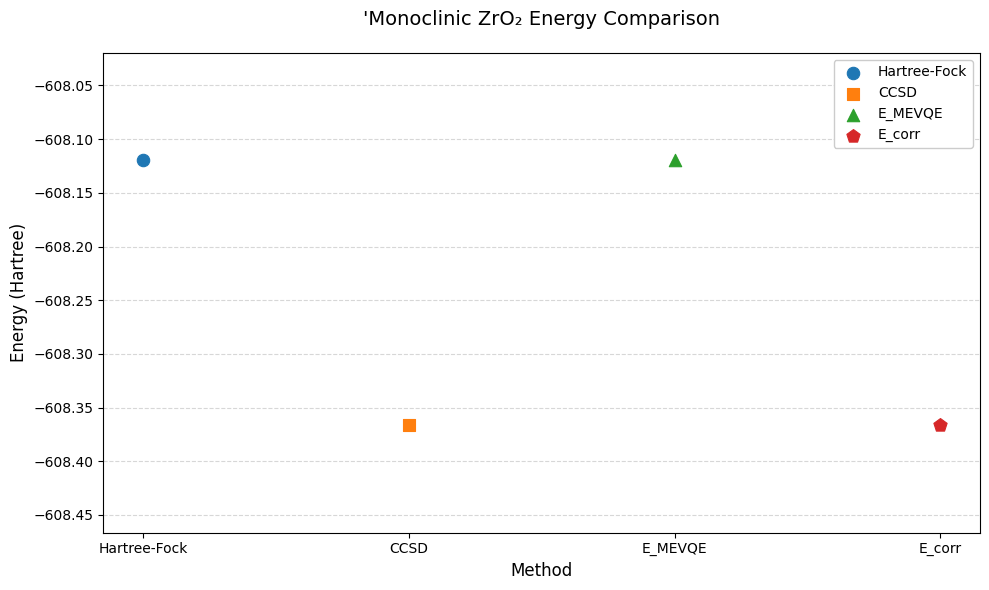

In [56]:
import matplotlib.pyplot as plt

# 数据
methods = ["Hartree-Fock", "CCSD", "E_MEVQE", "E_corr"]
energies = [-608.1196082141597, -608.3663660904948, -608.1196096046281, -608.3665162169106]  # Hartree

# 创建图形
plt.figure(figsize=(10, 6))

# 标记形状和颜色配置
markers = ['o', 's', '^', 'p']  # 圆形、正方形、三角形、五角星
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
marker_sizes = [80, 80, 80, 100]  # 五角星稍大以提高辨识度

# 绘制散点图（每个方法一个点）
# 绘制散点图（不同形状和颜色）
for i, (method, energy) in enumerate(zip(methods, energies)):
    plt.scatter(method, energy, 
                marker=markers[i], 
                color=colors[i], 
                s=marker_sizes[i], 
                label=method, 
                #edgecolor='black',  # 标记边框
                linewidth=0.8,      # 边框粗细
                zorder=3)

# 添加水平参考线（浅灰色虚线）
#for energy in energies:
#    plt.axhline(y=energy, color='gray', linestyle='-.', alpha=0.2, zorder=0.1)

# 坐标轴标签和标题
plt.xlabel("Method", fontsize=12)
plt.ylabel("Energy (Hartree)", fontsize=12)
plt.title("'Monoclinic ZrO₂ Energy Comparison", fontsize=14, pad=20)

# 调整纵坐标范围以突出差异
plt.ylim(min(energies) - 0.1, max(energies) + 0.1)

# 网格线（横向）
plt.grid(axis='y', linestyle='--', alpha=0.5)

# 显示图例（可选）
plt.legend(loc='upper right', framealpha=1)

plt.tight_layout()
#plt.savefig("./fig/energy_comparison_markers.png", dpi=300)  # 保存高清图
plt.show()

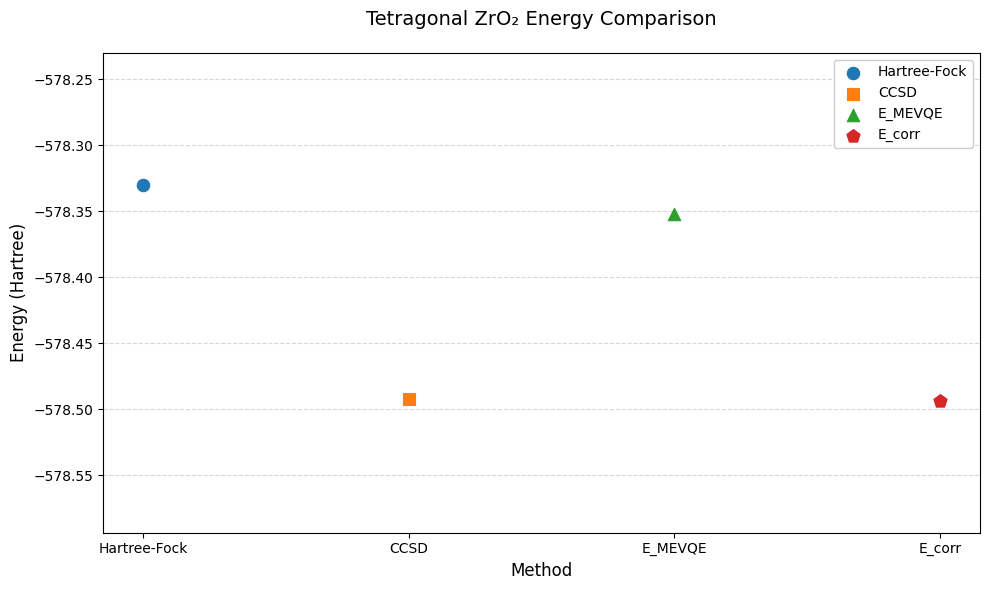

In [57]:
import matplotlib.pyplot as plt

# 数据
methods = ["Hartree-Fock", "CCSD", "E_MEVQE", "E_corr"]
energies = [
    -578.3300636454477,  # Hartree-Fock
    -578.492495326977,   # CCSD
    -578.3517871563753,  # CAS(5o,4e)
    -578.493388774724    # Etotal
]

# 创建图形
plt.figure(figsize=(10, 6))

# 标记形状和颜色配置
markers = ['o', 's', '^', 'p']  # 圆形、正方形、三角形、五角星
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
marker_sizes = [80, 80, 80, 100]  # 五角星稍大以提高辨识度

# 绘制散点图（每个方法一个点）
# 绘制散点图（不同形状和颜色）
for i, (method, energy) in enumerate(zip(methods, energies)):
    plt.scatter(method, energy, 
                marker=markers[i], 
                color=colors[i], 
                s=marker_sizes[i], 
                label=method, 
                #edgecolor='black',  # 标记边框
                linewidth=0.8,      # 边框粗细
                zorder=3)

# 添加水平参考线（浅灰色虚线）
#for energy in energies:
#    plt.axhline(y=energy, color='gray', linestyle='-.', alpha=0.2, zorder=0.1)

# 坐标轴标签和标题
plt.xlabel("Method", fontsize=12)
plt.ylabel("Energy (Hartree)", fontsize=12)
plt.title("Tetragonal ZrO₂ Energy Comparison", fontsize=14, pad=20)

# 调整纵坐标范围以突出差异
plt.ylim(min(energies) - 0.1, max(energies) + 0.1)

# 网格线（横向）
plt.grid(axis='y', linestyle='--', alpha=0.5)

# 显示图例（可选）
plt.legend(loc='upper right', framealpha=1)

plt.tight_layout()
#plt.savefig("./fig/t-energy_comparison_markers.png", dpi=300)  # 保存高清图
plt.show()

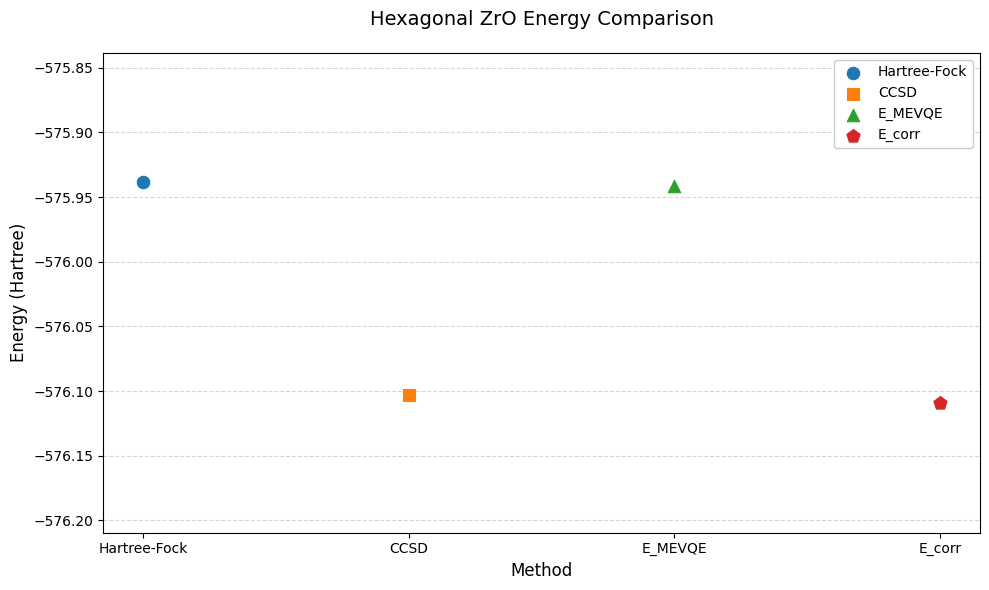

In [59]:
import matplotlib.pyplot as plt

# 数据
methods = ["Hartree-Fock", "CCSD", "E_MEVQE", "E_corr"]
energies = [
    -575.9385060022055,    # Hartree-Fock
    -576.1026903963094,    # CCSD
    -575.9416605442128,    # CAS(5o,4e)
    -576.10953342431053    # Etotal
]

# 创建图形
plt.figure(figsize=(10, 6))

# 标记形状和颜色配置
markers = ['o', 's', '^', 'p']  # 圆形、正方形、三角形、五角星
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
marker_sizes = [80, 80, 80, 100]  # 五角星稍大以提高辨识度

# 绘制散点图（每个方法一个点）
# 绘制散点图（不同形状和颜色）
for i, (method, energy) in enumerate(zip(methods, energies)):
    plt.scatter(method, energy, 
                marker=markers[i], 
                color=colors[i], 
                s=marker_sizes[i], 
                label=method, 
                #edgecolor='black',  # 标记边框
                linewidth=0.8,      # 边框粗细
                zorder=3)

# 添加水平参考线（浅灰色虚线）
#for energy in energies:
#    plt.axhline(y=energy, color='gray', linestyle='-.', alpha=0.2, zorder=0.1)

# 坐标轴标签和标题
plt.xlabel("Method", fontsize=12)
plt.ylabel("Energy (Hartree)", fontsize=12)
plt.title("Hexagonal ZrO Energy Comparison", fontsize=14, pad=20)

# 调整纵坐标范围以突出差异
plt.ylim(min(energies) - 0.1, max(energies) + 0.1)

# 网格线（横向）
plt.grid(axis='y', linestyle='--', alpha=0.5)

# 显示图例（可选）
plt.legend(loc='upper right', framealpha=1)

plt.tight_layout()
#plt.savefig("./fig/h-energy_comparison_markers.png", dpi=300)  # 保存高清图
plt.show()